# Wav3: 50–500 Hz energy ratio and GPL detection lengths

Recording: `SOCAL_H_76_230427_014845.x.wav` (wav3, 37.5 min, 200 kHz).

1. Run (or load) `GPL_Python` detections and whitened spectrograms for all 30 windows.
2. Compute the 50–500 Hz / total whitened energy ratio across time.
3. Plot the energy ratio and GPL detection lengths (durations) as a function of time.


In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.GPL_Python.gpl_outputs import load_detections_npy
from analysis.GPL_Python.gpl_signal import load_params_file
from analysis.GPL_Python.process_v4 import ProcessingOrchestrator

WAV = Path("/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav")
OUT = Path("/home/yfreund/whale_processing/LeiData/GPL_Python_outputs_wav3_contours")
STEM = WAV.stem
DET_PATH = OUT / f"Detections_{STEM}.npy"
CSV_PATH = OUT / f"CSV_{STEM}.csv"
NPY_DIR = OUT / "spectrogram_npy"
RECOMPUTE = False

BAND_LO = 50.0
BAND_HI = 500.0

plt.rcParams["figure.dpi"] = 120


In [2]:
# Compute GPL detections + whitened spectrograms if not already present (or if RECOMPUTE=True)
if RECOMPUTE or not DET_PATH.exists() or not CSV_PATH.exists():
    params_path = OUT / "params.json"
    params = load_params_file(params_path) if params_path.exists() else None
    ProcessingOrchestrator(OUT, freq_lo=10.0, freq_hi=10000.0, params=params).process(WAV)

det = load_detections_npy(DET_PATH)
calls = det["calls"]
csv = pd.read_csv(CSV_PATH)
print(f"Loaded {len(calls)} GPL detections ({len(csv)} CSV rows) from {OUT}")


Loaded 644 GPL detections (644 CSV rows) from /home/yfreund/whale_processing/LeiData/GPL_Python_outputs_wav3_contours


In [3]:
# Compute 50-500 Hz energy ratio for every spectrogram column across all windows
sidecars = sorted(NPY_DIR.glob(f"spwhiten_{STEM}_w*.json"))
assert sidecars, f"No whitened windows in {NPY_DIR}"

t_cols = []
ratio_cols = []

for sc in sidecars:
    meta = json.loads(sc.read_text())
    sp = np.load(NPY_DIR / f"{sc.stem}.npy").astype(np.float64)
    n_freq, n_time = sp.shape
    freqs = np.linspace(float(meta["start_freq"]), float(meta["end_freq"]), n_freq)
    band_mask = (freqs >= BAND_LO) & (freqs <= BAND_HI)

    energy_all = np.sum(sp * sp, axis=0)
    energy_band = np.sum(sp[band_mask] ** 2, axis=0)
    ratio = np.divide(energy_band, energy_all, out=np.zeros_like(energy_band), where=energy_all > 0)

    sr = float(meta["sample_freq"])
    hop = float(meta["overlap"])
    start_sample = float(meta["start_sample"])
    t = (start_sample - 1.0 + np.arange(n_time) * hop) / sr

    t_cols.append(t)
    ratio_cols.append(ratio)

t_sec = np.concatenate(t_cols)
ratio_col = np.concatenate(ratio_cols)
sr = float(json.loads(sidecars[0].read_text())["sample_freq"])

# Bin energy ratio into 5-second windows for a clean curve alongside per-column values
BIN_SEC = 5.0
t_bins = np.arange(0.0, t_sec.max() + BIN_SEC, BIN_SEC)
bin_idx = np.clip(np.digitize(t_sec, t_bins) - 1, 0, len(t_bins) - 2)
ratio_5s = np.array([
    ratio_col[bin_idx == i].mean() if np.any(bin_idx == i) else np.nan
    for i in range(len(t_bins) - 1)
])
t_5s = t_bins[:-1] + 0.5 * BIN_SEC

# Detection times and lengths (seconds)
det_start_sec = np.array([int(c["start_time"]) / sr for c in calls], dtype=float)
det_end_sec = np.array([int(c["end_time"]) / sr for c in calls], dtype=float)
det_mid_sec = 0.5 * (det_start_sec + det_end_sec)
det_len_sec = det_end_sec - det_start_sec

print(
    f"Columns: {len(t_sec)} ({t_sec.max()/60:.2f} min) | "
    f"mean 50-500 Hz ratio: {np.nanmean(ratio_col):.3f} | "
    f"detections: {len(det_len_sec)}, median len: {np.median(det_len_sec):.2f} s"
)


Columns: 18270 (37.50 min) | mean 50-500 Hz ratio: 0.172 | detections: 644, median len: 1.35 s


## Energy ratio (5 s and ±10 s windows) and detection lengths vs. time


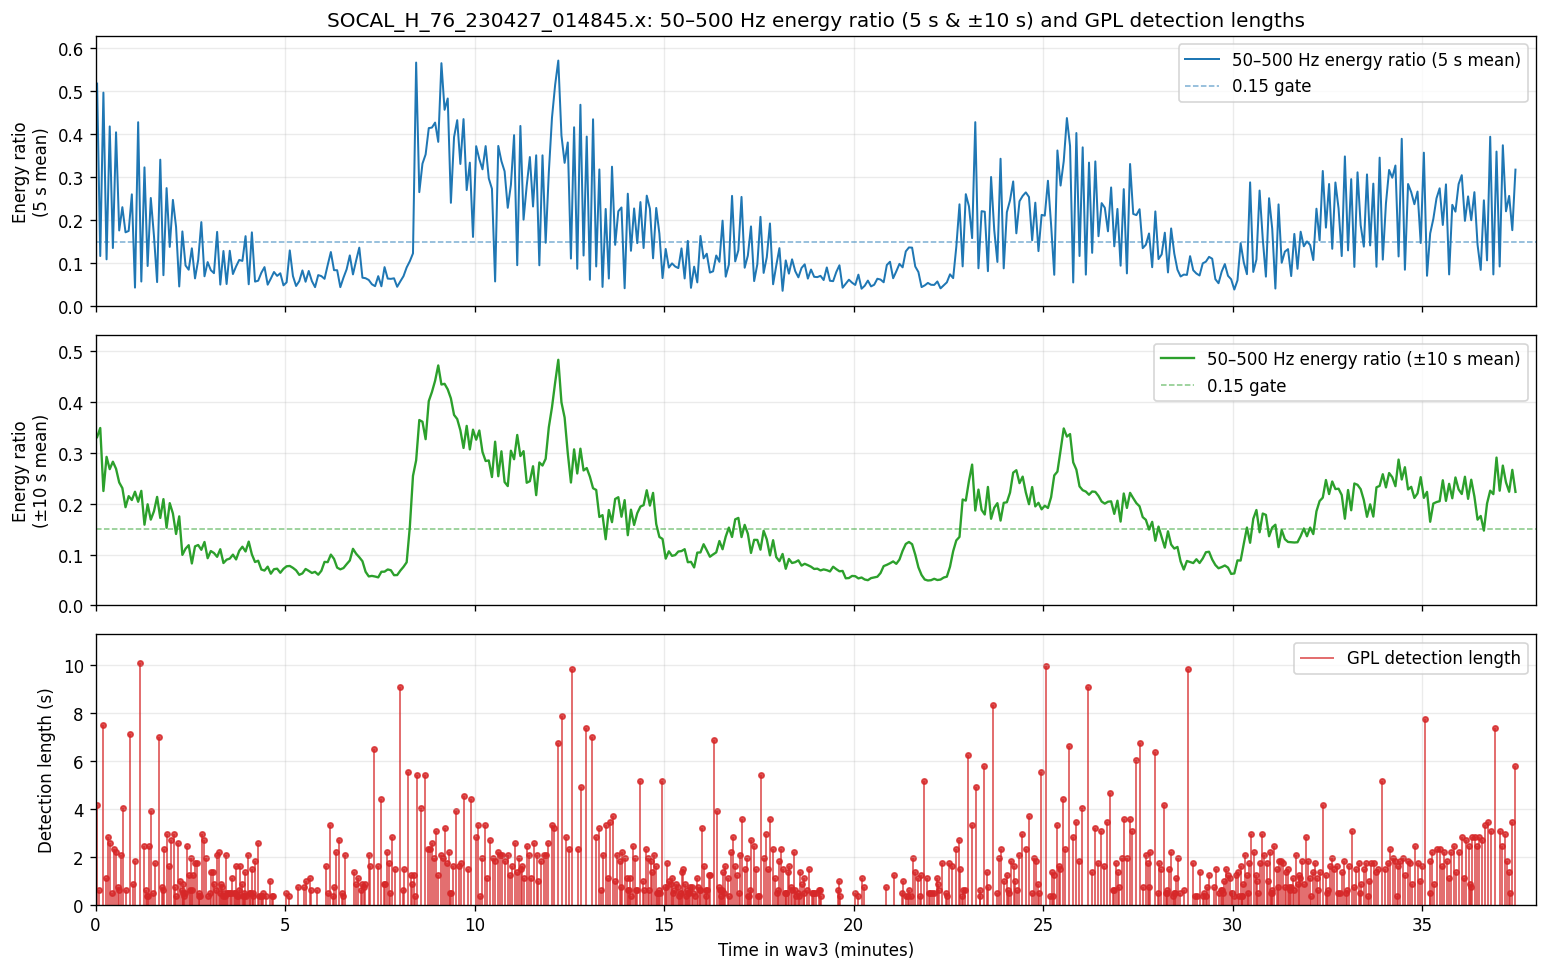

In [4]:
t_min_5s = t_5s / 60.0
det_mid_min = det_mid_sec / 60.0
n_min = int(np.ceil(t_sec.max() / 60.0))

# Rolling ±10 s (20 s total) mean of the 50-500 Hz energy ratio evaluated on the 5 s grid
ratio_pm10s = np.array([
    float(np.mean(ratio_col[(t_sec >= t0 - 10.0) & (t_sec <= t0 + 10.0)]))
    for t0 in t_5s
])

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(13, 8.2), sharex=True)

ax1.plot(t_min_5s, ratio_5s, color="#1f77b4", lw=1.2, label="50–500 Hz energy ratio (5 s mean)")
ax1.axhline(0.15, color="#1f77b4", ls="--", lw=0.9, alpha=0.6, label="0.15 gate")
ax1.set_ylabel("Energy ratio\n(5 s mean)")
ax1.set_ylim(0, max(0.5, float(np.nanmax(ratio_5s)) * 1.1))
ax1.grid(True, alpha=0.25)
ax1.legend(loc="upper right")
ax1.set_title(f"{STEM}: 50–500 Hz energy ratio (5 s & ±10 s) and GPL detection lengths")

ax2.plot(t_min_5s, ratio_pm10s, color="#2ca02c", lw=1.4, label="50–500 Hz energy ratio (±10 s mean)")
ax2.axhline(0.15, color="#2ca02c", ls="--", lw=0.9, alpha=0.6, label="0.15 gate")
ax2.set_ylabel("Energy ratio\n(±10 s mean)")
ax2.set_ylim(0, max(0.5, float(np.nanmax(ratio_pm10s)) * 1.1))
ax2.grid(True, alpha=0.25)
ax2.legend(loc="upper right")

ax3.vlines(det_mid_min, 0, det_len_sec, color="#d62728", lw=1.0, alpha=0.8, label="GPL detection length")
ax3.scatter(det_mid_min, det_len_sec, color="#d62728", s=10, alpha=0.8)
ax3.set_ylabel("Detection length (s)")
ax3.set_xlabel("Time in wav3 (minutes)")
ax3.set_xlim(0, n_min)
ax3.set_ylim(0, float(det_len_sec.max()) * 1.12)
ax3.grid(True, alpha=0.25)
ax3.legend(loc="upper right")

fig.tight_layout()
plt.show()


## Hypothesis test: are long detections correlated with high 50–500 Hz energy ratios?

For each GPL detection we compute the mean 50–500 Hz energy ratio over the detection's time span (`ratio_during`), over the surrounding ±2.5 s window (`ratio_local5s`), and over the surrounding ±10 s window (`ratio_local20s`), then test correlation with detection length using Pearson $r$, Spearman $\rho$, and a Mann–Whitney U test comparing long vs. short detections.


=== During detection (n=644) ===
  Pearson  r = +0.1524  (p = 1.037e-04)
  Spearman ρ = +0.1715  (p = 1.210e-05)
=== Local ±2.5 s window (n=644) ===
  Pearson  r = +0.3895  (p = 9.260e-25)
  Spearman ρ = +0.3021  (p = 4.629e-15)
=== Local ±10 s window (n=644) ===
  Pearson  r = +0.3130  (p = 4.175e-16)
  Spearman ρ = +0.4256  (p = 1.008e-29)

[±10 s window] Long detections (len >= 2.09 s, n=162): median ratio = 0.2071, mean = 0.2112
[±10 s window] Shorter detections (len < 2.09 s, n=482): median ratio = 0.1249, mean = 0.1502
[±10 s window] One-sided Mann-Whitney U (long > short): U = 55496.0, p = 4.821e-16


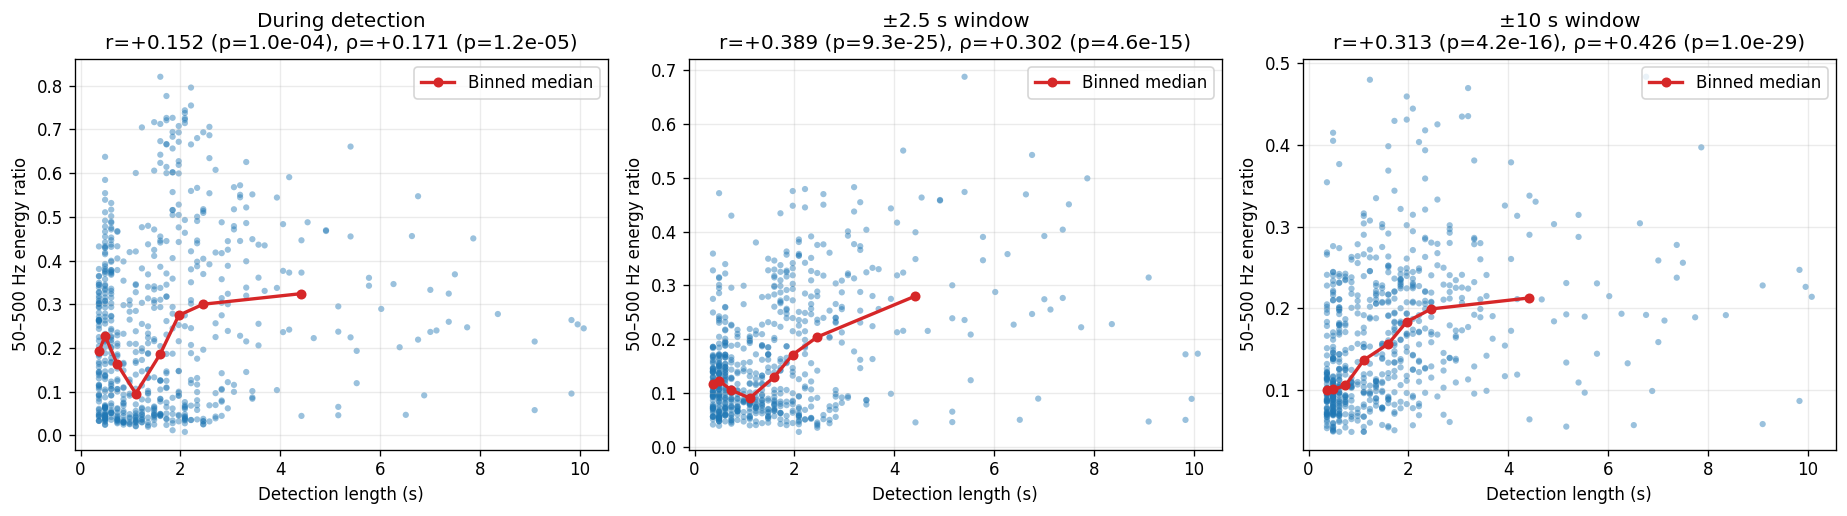

In [5]:
from scipy import stats

# Local 50-500 Hz energy ratio during each detection and in +/-2.5 s and +/-10 s windows
ratio_during = np.empty(len(det_len_sec), dtype=float)
ratio_local5s = np.empty(len(det_len_sec), dtype=float)
ratio_local20s = np.empty(len(det_len_sec), dtype=float)

for i, (s, e, m) in enumerate(zip(det_start_sec, det_end_sec, det_mid_sec)):
    mask_dur = (t_sec >= s) & (t_sec <= e)
    if np.any(mask_dur):
        ratio_during[i] = float(np.mean(ratio_col[mask_dur]))
    else:
        ratio_during[i] = float(ratio_col[np.argmin(np.abs(t_sec - m))])
    mask_5s = (t_sec >= m - 2.5) & (t_sec <= m + 2.5)
    ratio_local5s[i] = float(np.mean(ratio_col[mask_5s])) if np.any(mask_5s) else ratio_during[i]
    mask_20s = (t_sec >= m - 10.0) & (t_sec <= m + 10.0)
    ratio_local20s[i] = float(np.mean(ratio_col[mask_20s])) if np.any(mask_20s) else ratio_during[i]

for name, r_arr in [
    ("During detection", ratio_during),
    ("Local ±2.5 s window", ratio_local5s),
    ("Local ±10 s window", ratio_local20s),
]:
    pr, pp = stats.pearsonr(det_len_sec, r_arr)
    sr_val, sp_val = stats.spearmanr(det_len_sec, r_arr)
    print(f"=== {name} (n={len(det_len_sec)}) ===")
    print(f"  Pearson  r = {pr:+.4f}  (p = {pp:.3e})")
    print(f"  Spearman ρ = {sr_val:+.4f}  (p = {sp_val:.3e})")

# Compare top quartile (long) vs bottom 75% (shorter) detections for ±10 s window
q75 = float(np.percentile(det_len_sec, 75))
long_mask = det_len_sec >= q75
u_stat, u_p = stats.mannwhitneyu(ratio_local20s[long_mask], ratio_local20s[~long_mask], alternative="greater")
print(f"\n[±10 s window] Long detections (len >= {q75:.2f} s, n={long_mask.sum()}): "
      f"median ratio = {np.median(ratio_local20s[long_mask]):.4f}, mean = {np.mean(ratio_local20s[long_mask]):.4f}")
print(f"[±10 s window] Shorter detections (len < {q75:.2f} s, n={(~long_mask).sum()}): "
      f"median ratio = {np.median(ratio_local20s[~long_mask]):.4f}, mean = {np.mean(ratio_local20s[~long_mask]):.4f}")
print(f"[±10 s window] One-sided Mann-Whitney U (long > short): U = {u_stat:.1f}, p = {u_p:.3e}")

# Scatter + quantile-binned median trend
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

for ax, r_arr, title in [
    (axes[0], ratio_during, "During detection"),
    (axes[1], ratio_local5s, "±2.5 s window"),
    (axes[2], ratio_local20s, "±10 s window"),
]:
    pr, pp = stats.pearsonr(det_len_sec, r_arr)
    sr_val, sp_val = stats.spearmanr(det_len_sec, r_arr)
    ax.scatter(det_len_sec, r_arr, s=14, alpha=0.45, color="#1f77b4", edgecolors="none")

    edges = np.quantile(det_len_sec, np.linspace(0, 1, 9))
    bx, by = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (det_len_sec >= lo) & (det_len_sec <= hi)
        if np.any(m):
            bx.append(float(np.median(det_len_sec[m])))
            by.append(float(np.median(r_arr[m])))
    ax.plot(bx, by, "-o", color="#d62728", lw=2.0, ms=5, label="Binned median")

    ax.set_xlabel("Detection length (s)")
    ax.set_ylabel("50–500 Hz energy ratio")
    ax.set_title(f"{title}\nr={pr:+.3f} (p={pp:.1e}), ρ={sr_val:+.3f} (p={sp_val:.1e})")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper right")

fig.tight_layout()
plt.show()
